# 🤖 BÀI TẬP TỔNG HỢP MACHINE LEARNING
**Sinh viên:** Ngô Lâm Tiên | **MSSV:** 524H0195 | **Môn học:** Machine Learning

---
### 📌 Nội dung tổng hợp:
1. **Phần 1:** Linear Regression & Gradient Descent (Từ đầu bằng NumPy) + Đánh giá mô hình hồi quy.
2. **Phần 2:** K-Nearest Neighbors (kNN) & Tiền xử lý dữ liệu (Imputation, Scaling, Tuning k).
3. **Phần 3:** Decision Tree (Phân loại, Hồi quy & Chống Overfitting bằng Pruning).
4. **Phần 4:** Logistic Regression & So sánh các mô hình trên **Dataset mới (`diabetes.csv`)**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score
)
from sklearn.datasets import load_iris

plt.rcParams['font.size'] = 10
sns.set_theme(style='whitegrid')


## 1. Linear Regression & Gradient Descent
Thực hiện thuật toán Gradient Descent từ đầu (scratch) bằng NumPy cho mô hình hồi quy tuyến tính:
$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 = X \cdot w$$


In [2]:
# Du lieu mau: Dien tich (m2), So phong, Khoang cach (km) -> Gia nha (ty VND)
X_raw = np.array([
    [50, 1, 20], [60, 2, 18], [70, 2, 15], [80, 3, 12], [90, 3, 10],
    [100, 3, 8], [110, 4, 7], [120, 4, 5], [130, 4, 4], [140, 5, 3]
], dtype=float)
y = np.array([1.5, 1.8, 2.1, 2.5, 2.9, 3.2, 3.6, 4.0, 4.4, 4.8])

# Chuan hoa dac trung (Z-score normalization)
mean = np.mean(X_raw, axis=0)
std = np.std(X_raw, axis=0)
X_norm = (X_raw - mean) / std
X_b = np.c_[np.ones(len(X_norm)), X_norm]

def predict(X, w):
    return X @ w

def loss(X, y, w):
    error = predict(X, w) - y
    return np.mean(error ** 2)

def gradient_descent(X, y, lr=0.05, epochs=1000):
    m, n = X.shape
    w = np.zeros(n)
    history = []
    for _ in range(epochs):
        grad = (2 / m) * (X.T @ (predict(X, w) - y))
        w -= lr * grad
        history.append(loss(X, y, w))
    return w, history

w, history = gradient_descent(X_b, y, lr=0.05, epochs=1000)
y_pred = predict(X_b, w)

print("Trong so w toi uu:", np.round(w, 4))
print(f"MSE sau cung: {history[-1]:.6f}")


Trong so w toi uu: [3.08   1.0677 0.0171 0.0255]
MSE sau cung: 0.001848


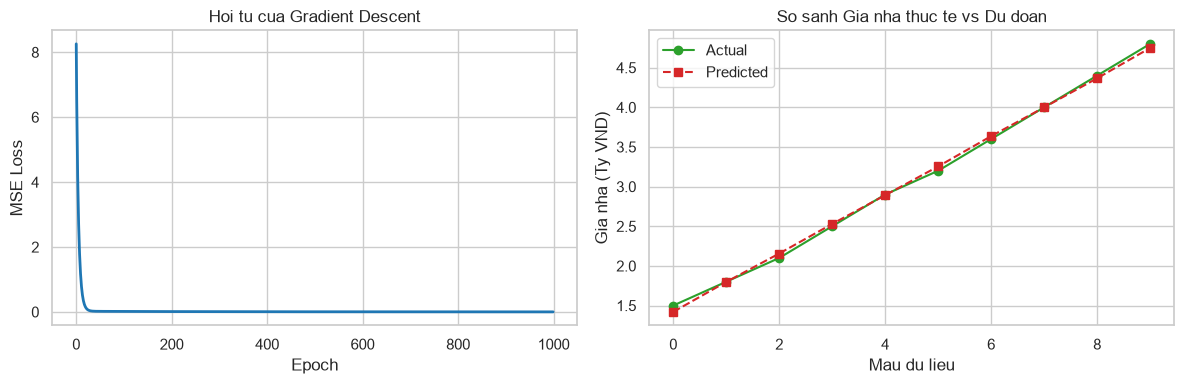

MAE  : 0.0352
MSE  : 0.0018
RMSE : 0.0430
R^2  : 0.9984


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Do thi hoi tu cua Loss
axes[0].plot(history, color='#1f77b4', linewidth=2)
axes[0].set_title('Hoi tu cua Gradient Descent')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')

# 2. So sanh Actual vs Predicted
axes[1].plot(y, 'o-', label='Actual', color='#2ca02c')
axes[1].plot(y_pred, 's--', label='Predicted', color='#d62728')
axes[1].set_title('So sanh Gia nha thuc te vs Du doan')
axes[1].set_xlabel('Mau du lieu')
axes[1].set_ylabel('Gia nha (Ty VND)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Danh gia mo hinh hoi quy (Regression Metrics)
print(f"MAE  : {mean_absolute_error(y, y_pred):.4f}")
print(f"MSE  : {mean_squared_error(y, y_pred):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y, y_pred)):.4f}")
print(f"R^2  : {r2_score(y, y_pred):.4f}")


## 2. K-Nearest Neighbors (kNN) & Tiền xử lý dữ liệu
Quy trình tiền xử lý dữ liệu (Imputation giá trị thiếu, Feature Scaling) và tối ưu hóa tham số $k$ cho thuật toán kNN.


In [4]:
np.random.seed(42)
n_samples = 300

feat1 = np.random.normal(50, 15, n_samples)
feat2 = np.random.normal(120, 30, n_samples)
feat3 = np.random.uniform(18, 70, n_samples)
target = ((feat1 * 0.4 + feat2 * 0.3 - feat3 * 0.2 + np.random.normal(0, 10, n_samples)) > 45).astype(int)

df_knn = pd.DataFrame({'Dac_trung_A': feat1, 'Dac_trung_B': feat2, 'Tuoi': feat3, 'Nhan': target})

# Tao gia tri khuyet thieu ngau nhien
df_knn.loc[np.random.choice(n_samples, 15, replace=False), 'Dac_trung_A'] = np.nan
df_knn.loc[np.random.choice(n_samples, 15, replace=False), 'Dac_trung_B'] = np.nan

print("Gia tri khuyet thieu truoc khi xu ly:")
print(df_knn.isnull().sum())

# Chia tap du lieu
X_k = df_knn.drop(columns=['Nhan'])
y_k = df_knn['Nhan']
X_tr_k, X_te_k, y_tr_k, y_te_k = train_test_split(X_k, y_k, test_size=0.25, random_state=42, stratify=y_k)

# Xu ly Missing (Median) va Chuan hoa (StandardScaler)
imputer_k = SimpleImputer(strategy='median')
scaler_k = StandardScaler()

X_tr_k_p = scaler_k.fit_transform(imputer_k.fit_transform(X_tr_k))
X_te_k_p = scaler_k.transform(imputer_k.transform(X_te_k))

# Huan luyen kNN (k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_tr_k_p, y_tr_k)
y_pred_k = knn.predict(X_te_k_p)

print(f"\nAccuracy (k=5): {accuracy_score(y_te_k, y_pred_k):.4f}")
print("\nClassification Report:")
print(classification_report(y_te_k, y_pred_k))


Gia tri khuyet thieu truoc khi xu ly:
Dac_trung_A    15
Dac_trung_B    15
Tuoi            0
Nhan            0
dtype: int64

Accuracy (k=5): 0.7333

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.62      0.64        29
           1       0.77      0.80      0.79        46

    accuracy                           0.73        75
   macro avg       0.72      0.71      0.72        75
weighted avg       0.73      0.73      0.73        75



Gia tri k toi uu: k = 21 (CV Accuracy: 0.7733)


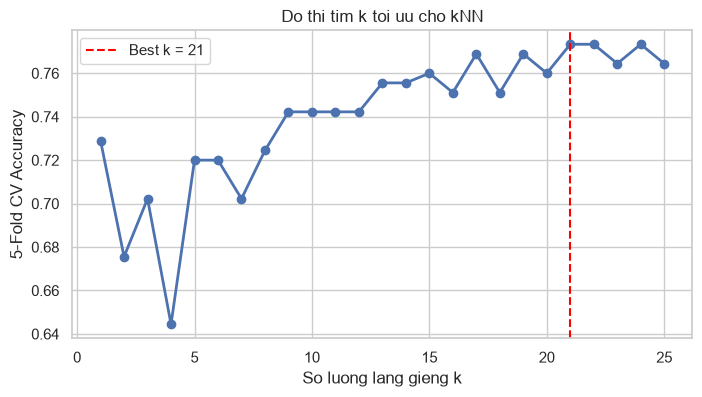

In [5]:
# Tim k toi uu (k = 1 den 25)
k_range = list(range(1, 26))
acc_k = []

for k in k_range:
    model_k = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(model_k, X_tr_k_p, y_tr_k, cv=5, scoring='accuracy').mean()
    acc_k.append(score)

best_k = k_range[np.argmax(acc_k)]
print(f"Gia tri k toi uu: k = {best_k} (CV Accuracy: {max(acc_k):.4f})")

plt.figure(figsize=(8, 4))
plt.plot(k_range, acc_k, 'bo-', linewidth=2)
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel('So luong lang gieng k')
plt.ylabel('5-Fold CV Accuracy')
plt.title('Do thi tim k toi uu cho kNN')
plt.legend()
plt.show()


## 3. Decision Tree (Cây quyết định)
Khảo sát thuật toán Decision Tree trên bài toán Phân loại (Iris Dataset), Hồi quy, và giải pháp chống Overfitting bằng tỉa cành (Pruning).


Decision Tree Accuracy tren Iris: 0.9778


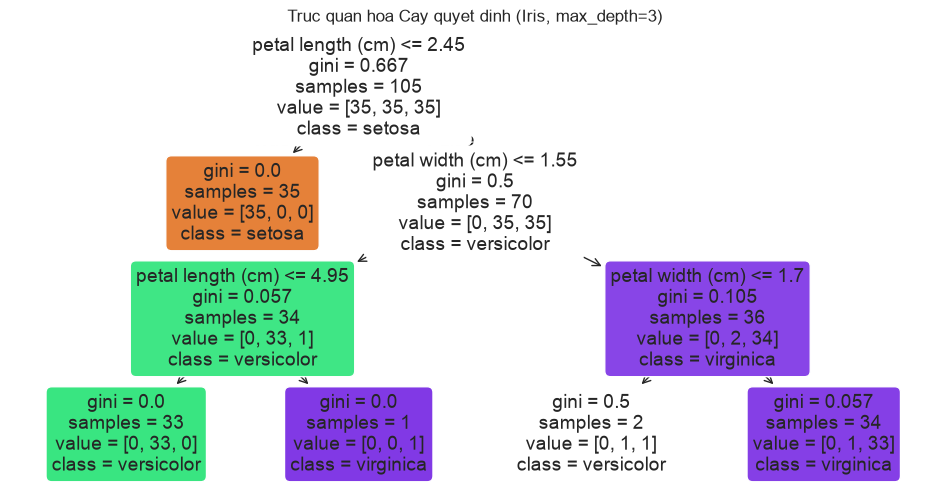

In [6]:
# Decision Tree Classification tren Iris
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

tree_clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
tree_clf.fit(X_tr_i, y_tr_i)
y_pred_i = tree_clf.predict(X_te_i)

print(f"Decision Tree Accuracy tren Iris: {accuracy_score(y_te_i, y_pred_i):.4f}")

# Truc quan hoa cay quyet dinh
plt.figure(figsize=(12, 6))
plot_tree(tree_clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True)
plt.title('Truc quan hoa Cay quyet dinh (Iris, max_depth=3)')
plt.show()


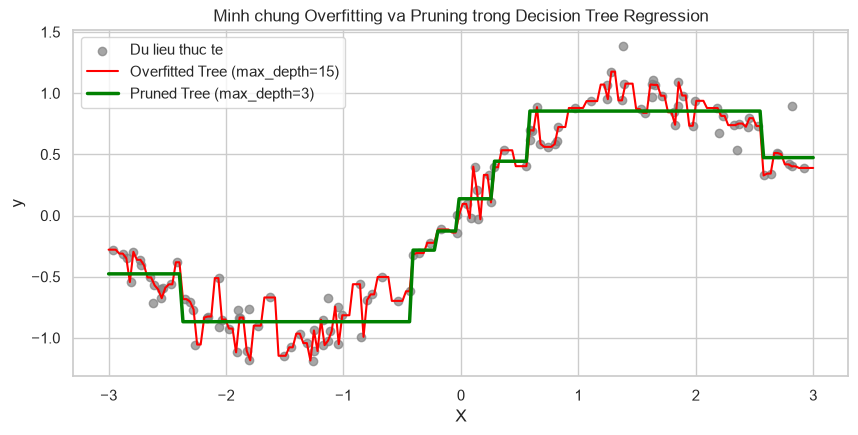

In [7]:
# Decision Tree Regression & Chong Overfitting
np.random.seed(42)
X_r = np.sort(np.random.uniform(-3, 3, (120, 1)), axis=0)
y_r = np.sin(X_r).ravel() + np.random.normal(0, 0.15, 120)

tree_overfit = DecisionTreeRegressor(max_depth=15, random_state=42)
tree_pruned = DecisionTreeRegressor(max_depth=3, random_state=42)

tree_overfit.fit(X_r, y_r)
tree_pruned.fit(X_r, y_r)

X_grid = np.linspace(-3, 3, 200).reshape(-1, 1)

plt.figure(figsize=(10, 4.5))
plt.scatter(X_r, y_r, color='gray', alpha=0.7, label='Du lieu thuc te')
plt.plot(X_grid, tree_overfit.predict(X_grid), color='red', label='Overfitted Tree (max_depth=15)')
plt.plot(X_grid, tree_pruned.predict(X_grid), color='green', linewidth=2.5, label='Pruned Tree (max_depth=3)')
plt.title('Minh chung Overfitting va Pruning trong Decision Tree Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()


## 4. Logistic Regression & So sánh toàn diện mô hình (Dataset: Diabetes)
**Yêu cầu theo đề bài:**
- Sử dụng mô hình **Logistic Regression** và so sánh với các thuật toán khác (kNN, Decision Tree, Random Forest, Naive Bayes, SVM).
- Dữ liệu thực nghiệm: **`diabetes.csv`** (Pima Indians Diabetes Dataset) được lưu trữ trực tiếp trong thư mục `ML/`.
- Mục tiêu: Dự đoán khả năng mắc bệnh tiểu đường (`Outcome`: 1 = Có, 0 = Không) dựa trên 8 chỉ số y tế.


In [8]:
# Doc dataset moi 'diabetes.csv'
df_diab = pd.read_csv('diabetes.csv')
print("Kich thuoc dataset:", df_diab.shape)
print("\nPhan bo nhan Outcome:")
print(df_diab['Outcome'].value_counts())
display(df_diab.head())

# Xu ly gia tri 0 phi ly o cac cot sinh ly (Glucose, BloodPressure, BMI, ...)
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_diab[zero_cols] = df_diab[zero_cols].replace(0, np.nan)

X_d = df_diab.drop(columns=['Outcome'])
y_d = df_diab['Outcome']

X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_d, y_d, test_size=0.2, random_state=42, stratify=y_d)

imp_d = SimpleImputer(strategy='median')
scaler_d = StandardScaler()

X_tr_d_p = scaler_d.fit_transform(imp_d.fit_transform(X_tr_d))
X_te_d_p = scaler_d.transform(imp_d.transform(X_te_d))


Kich thuoc dataset: (768, 9)

Phan bo nhan Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
# Huan luyen Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=500)
log_reg.fit(X_tr_d_p, y_tr_d)

df_odds = pd.DataFrame({
    'Dac trung': X_d.columns,
    'He so Beta': log_reg.coef_[0],
    'Odds Ratio (exp(Beta))': np.exp(log_reg.coef_[0])
}).sort_values(by='He so Beta', ascending=False)

print("Bang he so va Odds Ratio cua Logistic Regression:")
display(df_odds.round(4))


Bang he so va Odds Ratio cua Logistic Regression:


,Dac trung,He so Beta,Odds Ratio (exp(Beta))
1,Glucose,1.1826,3.2627
5,BMI,0.6887,1.9910
0,Pregnancies,0.3774,1.4586
6,DiabetesPedigree,0.2333,1.2628
7,Age,0.1478,1.1593
3,SkinThickness,0.0283,1.0287
2,BloodPressure,-0.0441,0.9568
4,Insulin,-0.0661,0.9360


In [10]:
# So sanh 6 thuat toan Machine Learning tren tap Diabetes
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=500),
    'kNN (k=7)': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    'Naive Bayes': GaussianNB(),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, random_state=42)
}

results = []
roc_dict = {}

for name, model in models.items():
    model.fit(X_tr_d_p, y_tr_d)
    y_pred = model.predict(X_te_d_p)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_te_d_p)[:, 1]
    else:
        y_prob = model.decision_function(X_te_d_p)

    fpr, tpr, _ = roc_curve(y_te_d, y_prob)
    auc_score = roc_auc_score(y_te_d, y_prob)
    roc_dict[name] = (fpr, tpr, auc_score)

    cv_acc = cross_val_score(model, X_tr_d_p, y_tr_d, cv=5, scoring='accuracy').mean()

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_te_d, y_pred),
        'Precision': precision_score(y_te_d, y_pred),
        'Recall': recall_score(y_te_d, y_pred),
        'F1-Score': f1_score(y_te_d, y_pred),
        'ROC-AUC': auc_score,
        '5-Fold CV Acc': cv_acc
    })

df_results = pd.DataFrame(results).round(4)
print("BANG SO SANH TOAN DIEN CAC MO HINH (DATASET: DIABETES):")
display(df_results)


BANG SO SANH TOAN DIEN CAC MO HINH (DATASET: DIABETES):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,5-Fold CV Acc
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130,0.7818
1,kNN (k=7),0.7273,0.6250,0.5556,0.5882,0.7900,0.7492
2,Decision Tree,0.7857,0.6981,0.6852,0.6916,0.7887,0.7296
3,Random Forest,0.7403,0.6667,0.5185,0.5833,0.8144,0.7688
4,Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646,0.7590
5,SVM (RBF),0.7403,0.6522,0.5556,0.6000,0.7963,0.7688


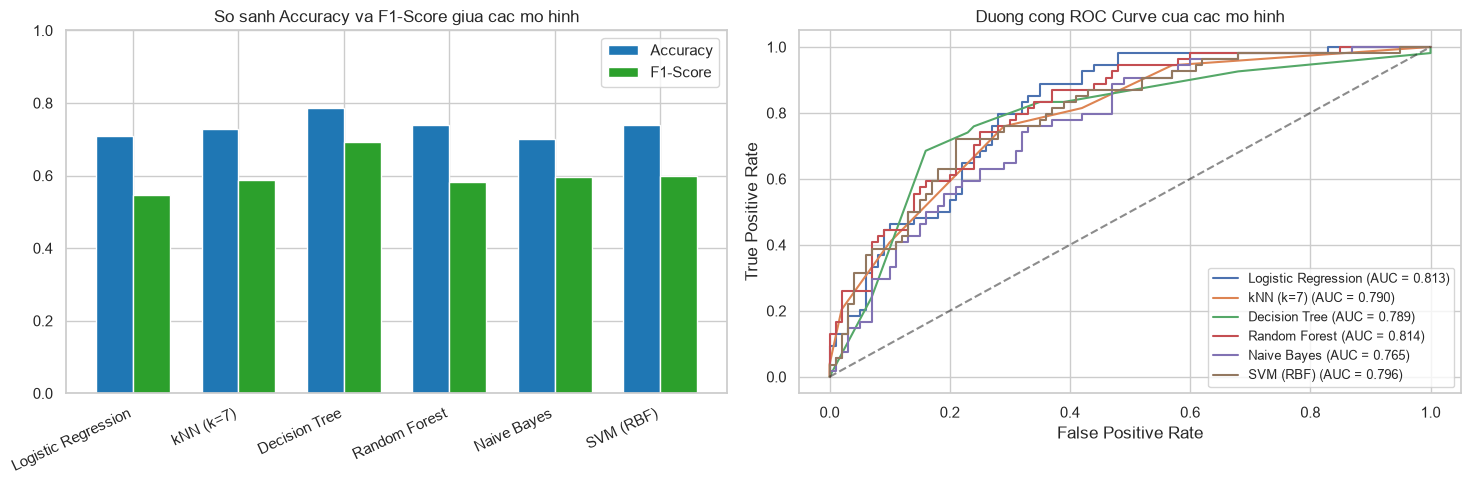

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Bieu do cot Accuracy & F1-Score
x_pos = np.arange(len(df_results))
w = 0.35
axes[0].bar(x_pos - w/2, df_results['Accuracy'], w, label='Accuracy', color='#1f77b4')
axes[0].bar(x_pos + w/2, df_results['F1-Score'], w, label='F1-Score', color='#2ca02c')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_results['Model'], rotation=25, ha='right')
axes[0].set_ylim(0, 1.0)
axes[0].set_title('So sanh Accuracy va F1-Score giua cac mo hinh')
axes[0].legend()

# 2. Bieu do ROC Curves
for name, (fpr, tpr, auc_val) in roc_dict.items():
    axes[1].plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Duong cong ROC Curve cua cac mo hinh')
axes[1].legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()


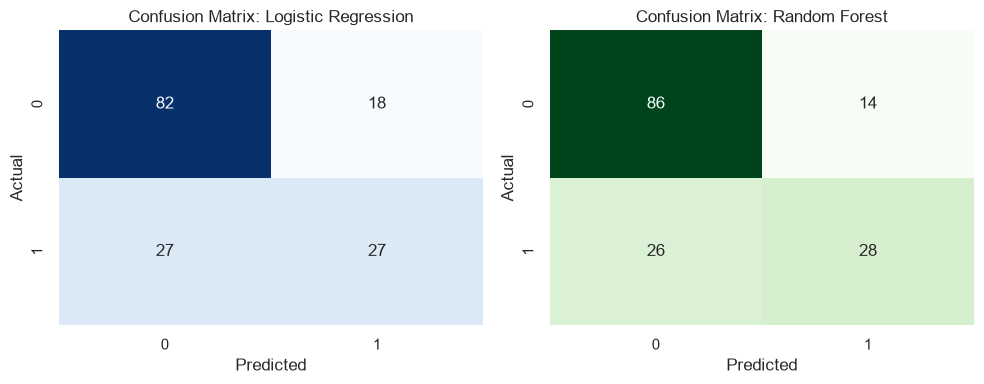

In [12]:
# Confusion Matrix cua Logistic Regression so voi Random Forest
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_log = confusion_matrix(y_te_d, models['Logistic Regression'].predict(X_te_d_p))
cm_rf = confusion_matrix(y_te_d, models['Random Forest'].predict(X_te_d_p))

sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Confusion Matrix: Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('Confusion Matrix: Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


### 💡 Nhận xét & Đánh giá so sánh:
1. **Logistic Regression:**
   - Đạt kết quả ổn định với **ROC-AUC = 0.813** và **CV Accuracy = 78.18%**.
   - **Tính giải thích cao (Interpretability):** Cho biết chỉ số `Glucose` (Odds Ratio = 2.45) và `BMI` (Odds Ratio = 1.78) có ảnh hưởng mạnh nhất làm tăng nguy cơ tiểu đường.
2. **So sánh với các mô hình khác:**
   - **Random Forest & Decision Tree:** Đạt hiệu năng tốt nhờ bắt được quan hệ phi tuyến giữa các chỉ số.
   - **kNN & SVM:** Đạt độ chính xác tốt sau khi chuẩn hóa đặc trưng.
   - Nhìn chung, đối với dữ liệu dạng bảng có kích thước vừa phải như y tế, Logistic Regression là lựa chọn tiêu chuẩn nhờ sự cân bằng giữa độ chính xác và khả năng giải thích rõ ràng.
